In [2]:
# NeuroGraphX Step 1 — brain-only longitudinal data + patient-level split
#
# Loads ADNI brain visit data, keeps ST* brain features with <=50% missingness,
# builds a patient-level 80/10/10 TRAIN/VAL/TEST split (no patient in >1 split),
# fits imputation + standardization on TRAIN only, and builds a temporal graph
# connecting consecutive visits of the same patient.

import os
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

INPUT_PATH = "/Users/sameersalim/neeuro/ADNI_UCSFFSX7_Clean_Brain_Visit_Dataset.csv"
OUTPUT_DIR = "/Users/sameersalim/neeuro/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

NODE_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Nodes_Step1.csv")
EDGE_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Edges_Step1.csv")
FEATURE_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Feature_List_Step1.txt")
TRAIN_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Train.csv")
VAL_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Validation.csv")
TEST_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Test.csv")
SCALER_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Scaler.npz")
IMPUTER_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Imputer.npz")

RANDOM_SEED = 42

print("NEUROGRAPHX — STEP 1: brain-only data prep")

df = pd.read_csv(INPUT_PATH, low_memory=False)
print(f"Loaded {df.shape[0]} visits, {df.shape[1]} columns")

required = ["RID", "EXAMDATE", "FUTURE_ALZHEIMER_LABEL"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Brain features: ST* columns with <=50% missingness
brain_features = [c for c in df.columns if c.startswith("ST")]
if not brain_features:
    raise ValueError("No ST* brain features found.")
missing_pct = df[brain_features].isna().mean() * 100
brain_features = [c for c in brain_features if missing_pct[c] <= 50]
print(f"Brain features retained: {len(brain_features)}")

# Dates + chronological ordering
df["EXAMDATE"] = pd.to_datetime(df["EXAMDATE"], errors="coerce")
if df["EXAMDATE"].isna().any():
    raise ValueError("EXAMDATE contains missing/invalid values.")
df = df.sort_values(["RID", "EXAMDATE"]).reset_index(drop=True)

df["VISIT_NUMBER"] = df.groupby("RID").cumcount() + 1
baseline_date = df.groupby("RID")["EXAMDATE"].transform("min")
df["TIME_FROM_BASELINE_YEARS"] = (df["EXAMDATE"] - baseline_date).dt.days / 365.25
df["TIME_GAP_YEARS"] = (df.groupby("RID")["EXAMDATE"].diff().dt.days / 365.25).fillna(0)

if df["FUTURE_ALZHEIMER_LABEL"].isna().any():
    raise ValueError("FUTURE_ALZHEIMER_LABEL contains missing values.")

# Patient-level 80/10/10 split — no patient may appear in more than one split
rng = np.random.RandomState(RANDOM_SEED)
patients = df["RID"].unique()
rng.shuffle(patients)
n_train = int(0.80 * len(patients))
n_val = int(0.10 * len(patients))
train_set = set(patients[:n_train])
val_set = set(patients[n_train:n_train + n_val])
test_set = set(patients[n_train + n_val:])

assert not (train_set & val_set) and not (train_set & test_set) and not (val_set & test_set), \
    "Patient-level leakage across splits."

df["SPLIT"] = np.select(
    [df["RID"].isin(train_set), df["RID"].isin(val_set), df["RID"].isin(test_set)],
    ["TRAIN", "VAL", "TEST"],
    default="UNKNOWN",
)
assert (df["SPLIT"] != "UNKNOWN").all(), "Some patients were not assigned to a split."
print("Patients:", {s: int(df.loc[df.SPLIT == s, "RID"].nunique()) for s in ["TRAIN", "VAL", "TEST"]})
print("Visits  :", df["SPLIT"].value_counts().to_dict())

# Train-only imputation + standardization
train_mask = df["SPLIT"] == "TRAIN"
imputer = SimpleImputer(strategy="median").fit(df.loc[train_mask, brain_features])
df[brain_features] = imputer.transform(df[brain_features])

scaler = StandardScaler().fit(df.loc[train_mask, brain_features])
df[brain_features] = scaler.transform(df[brain_features])

assert df[brain_features].isna().sum().sum() == 0
assert np.isfinite(df[brain_features].to_numpy()).all()

# Temporal graph: consecutive visits of the same patient (earlier -> later)
df["NODE_ID"] = np.arange(len(df))
edges = []
for rid, patient_df in df.groupby("RID"):
    node_ids = patient_df.sort_values("EXAMDATE")["NODE_ID"].tolist()
    for src, tgt in zip(node_ids[:-1], node_ids[1:]):
        edges.append({"RID": rid, "SOURCE_NODE": src, "TARGET_NODE": tgt})
edges_df = pd.DataFrame(edges)
print(f"Temporal edges: {len(edges_df)}")

# Save outputs
node_columns = (
    ["NODE_ID", "RID", "EXAMDATE", "VISIT_NUMBER", "TIME_FROM_BASELINE_YEARS",
     "TIME_GAP_YEARS", "SPLIT", "FUTURE_ALZHEIMER_LABEL"]
    + brain_features
)
node_df = df[node_columns].copy()

for split_name, path in [("TRAIN", TRAIN_OUTPUT), ("VAL", VAL_OUTPUT), ("TEST", TEST_OUTPUT)]:
    node_df[node_df["SPLIT"] == split_name].to_csv(path, index=False)

node_df.to_csv(NODE_OUTPUT, index=False)
edges_df.to_csv(EDGE_OUTPUT, index=False)

with open(FEATURE_OUTPUT, "w") as f:
    f.write("\n".join(brain_features))

np.savez(SCALER_OUTPUT, mean=scaler.mean_, scale=scaler.scale_,
          features=np.array(brain_features, dtype=object))
np.savez(IMPUTER_OUTPUT, statistics=imputer.statistics_,
          features=np.array(brain_features, dtype=object))

print(f"\nSTEP 1 COMPLETE — patients: {df['RID'].nunique()}, visits: {len(df)}, "
      f"brain features: {len(brain_features)}, temporal edges: {len(edges_df)}")
print(f"Nodes saved: {NODE_OUTPUT}")
print(f"Edges saved: {EDGE_OUTPUT}")


NEUROGRAPHX — STEP 1: brain-only data prep
Loaded 12290 visits, 86 columns
Brain features retained: 36
Patients: {'TRAIN': 2543, 'VAL': 317, 'TEST': 319}
Visits  : {'TRAIN': 9945, 'VAL': 1219, 'TEST': 1126}


/var/folders/6x/659rn5gj76j50ymjfc6f4psh0000gn/T/ipykernel_18786/2403407211.py:48: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["EXAMDATE"] = pd.to_datetime(df["EXAMDATE"], errors="coerce")


Temporal edges: 9111

STEP 1 COMPLETE — patients: 3179, visits: 12290, brain features: 36, temporal edges: 9111
Nodes saved: /Users/sameersalim/neeuro/output/NeuroGraphX_Brain_Nodes_Step1.csv
Edges saved: /Users/sameersalim/neeuro/output/NeuroGraphX_Brain_Edges_Step1.csv


In [3]:
# NeuroGraphX Step 2 — GraphSAGE on the brain-only temporal graph -> 64-D embeddings
#
# Step 1 already imputed/standardized the brain features and built the temporal
# edges (earlier visit -> later visit, same patient). Step 2 does not repeat
# either step; it only trains a GNN classifier and extracts its embeddings.

import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
)
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv

OUTPUT_DIR = Path("/Users/sameersalim/neeuro/output")
NODES_PATH = OUTPUT_DIR / "NeuroGraphX_Brain_Nodes_Step1.csv"
EDGES_PATH = OUTPUT_DIR / "NeuroGraphX_Brain_Edges_Step1.csv"
EMBEDDING_OUTPUT = OUTPUT_DIR / "NeuroGraphX_Brain_GNN_Embeddings.csv"
MODEL_OUTPUT = OUTPUT_DIR / "NeuroGraphX_Brain_GNN_Model.pt"
HISTORY_OUTPUT = OUTPUT_DIR / "NeuroGraphX_Brain_GNN_Training_History.csv"
METRICS_OUTPUT = OUTPUT_DIR / "NeuroGraphX_Brain_GNN_Test_Metrics.csv"

RANDOM_SEED = 42
HIDDEN_DIM, EMBEDDING_DIM, DROPOUT = 128, 64, 0.30
LEARNING_RATE, WEIGHT_DECAY = 1e-3, 1e-4
EPOCHS, PATIENCE, GRADIENT_CLIP = 300, 40, 2.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("NEUROGRAPHX — STEP 2: GraphSAGE brain embeddings | device:", DEVICE)

nodes = pd.read_csv(NODES_PATH, low_memory=False)
edges = pd.read_csv(EDGES_PATH, low_memory=False)
nodes["EXAMDATE"] = pd.to_datetime(nodes["EXAMDATE"], errors="coerce")

brain_features = [c for c in nodes.columns if c.startswith("ST")]
X = nodes[brain_features].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
assert np.isfinite(X).all(), "Step 1 output must already be imputed/standardized."

y = torch.tensor(pd.to_numeric(nodes["FUTURE_ALZHEIMER_LABEL"]).astype(int).values, dtype=torch.long)

split = nodes["SPLIT"].astype(str).str.upper()
train_mask = torch.tensor((split == "TRAIN").values)
val_mask = torch.tensor((split == "VAL").values)
test_mask = torch.tensor((split == "TEST").values)

# Patient-level leakage check
rid_by_split = {s: set(nodes.loc[(split == s).values, "RID"]) for s in ["TRAIN", "VAL", "TEST"]}
assert not (rid_by_split["TRAIN"] & rid_by_split["VAL"])
assert not (rid_by_split["TRAIN"] & rid_by_split["TEST"])
assert not (rid_by_split["VAL"] & rid_by_split["TEST"])
print(f"Patients — train: {len(rid_by_split['TRAIN'])} val: {len(rid_by_split['VAL'])} "
      f"test: {len(rid_by_split['TEST'])}")

# Directed temporal edges (earlier visit -> later visit).
# Same-patient adjacency is guaranteed by how Step 1 built these edges.
node_id_to_index = pd.Series(np.arange(len(nodes)), index=nodes["NODE_ID"].values)
edge_index = torch.tensor(
    np.stack([
        edges["SOURCE_NODE"].map(node_id_to_index).to_numpy(),
        edges["TARGET_NODE"].map(node_id_to_index).to_numpy(),
    ]),
    dtype=torch.long,
)

graph = Data(x=torch.tensor(X), edge_index=edge_index, y=y)
graph.train_mask, graph.val_mask, graph.test_mask = train_mask, val_mask, test_mask
graph = graph.to(DEVICE)
print(f"Graph: {graph.num_nodes} nodes, {graph.num_edges} edges, {graph.num_node_features} features")


class BrainGraphSAGE(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, embedding_dim=64, dropout=0.30):
        super().__init__()
        self.conv1 = SAGEConv(input_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, embedding_dim)
        self.classifier = nn.Linear(embedding_dim, 2)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(F.relu(self.conv1(x, edge_index)), p=self.dropout, training=self.training)
        embedding = F.relu(self.conv2(x, edge_index))
        return embedding, self.classifier(embedding)


model = BrainGraphSAGE(len(brain_features), HIDDEN_DIM, EMBEDDING_DIM, DROPOUT).to(DEVICE)
print(model)

train_labels = y[train_mask]
class_counts = torch.bincount(train_labels, minlength=2).float()
class_weights = class_counts.sum() / (2.0 * class_counts)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def calculate_metrics(y_true, y_prob, threshold=0.5):
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


print("\nTraining GraphSAGE...")
best_val_auc, best_state, best_epoch, no_improve = -np.inf, None, None, 0
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    _, logits = model(graph.x, graph.edge_index)
    train_loss = criterion(logits[graph.train_mask], graph.y[graph.train_mask])
    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRADIENT_CLIP)
    optimizer.step()

    model.eval()
    with torch.no_grad():
        _, val_logits = model(graph.x, graph.edge_index)
        val_loss = criterion(val_logits[graph.val_mask], graph.y[graph.val_mask])
        val_prob = torch.softmax(val_logits, dim=1)[:, 1]
        val_metrics = calculate_metrics(
            graph.y[graph.val_mask].cpu().numpy(), val_prob[graph.val_mask].cpu().numpy()
        )

    history.append({
        "epoch": epoch, "train_loss": train_loss.item(), "val_loss": val_loss.item(),
        "val_roc_auc": val_metrics["ROC_AUC"], "val_pr_auc": val_metrics["PR_AUC"],
    })

    if val_metrics["ROC_AUC"] > best_val_auc:
        best_val_auc, best_epoch, no_improve = val_metrics["ROC_AUC"], epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        no_improve += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:03d} | Train {train_loss.item():.4f} | Val {val_loss.item():.4f} "
              f"| Val ROC-AUC {val_metrics['ROC_AUC']:.4f}")

    if no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best epoch {best_epoch})")
        break

model.load_state_dict(best_state)
pd.DataFrame(history).to_csv(HISTORY_OUTPUT, index=False)
print(f"Best epoch: {best_epoch} | Best validation ROC-AUC: {best_val_auc:.6f}")

model.eval()
with torch.no_grad():
    final_embedding, final_logits = model(graph.x, graph.edge_index)
    final_prob = torch.softmax(final_logits, dim=1)[:, 1]

test_metrics = calculate_metrics(
    graph.y[graph.test_mask].cpu().numpy(), final_prob[graph.test_mask].cpu().numpy()
)
print("\nFinal test performance:")
for k, v in test_metrics.items():
    print(f"  {k:20s}: {v}")
pd.DataFrame([test_metrics]).to_csv(METRICS_OUTPUT, index=False)

embedding_np = final_embedding.cpu().numpy()
assert np.isfinite(embedding_np).all()

output = pd.DataFrame({
    "NODE_ID": nodes["NODE_ID"].values,
    "RID": nodes["RID"].values,
    "EXAMDATE": nodes["EXAMDATE"].dt.strftime("%Y-%m-%d"),
})
for col in ["VISIT_NUMBER", "TIME_FROM_BASELINE_YEARS", "TIME_GAP_YEARS"]:
    if col in nodes.columns:
        output[col] = nodes[col].values
output["SPLIT"] = nodes["SPLIT"].values
output["FUTURE_ALZHEIMER_LABEL"] = nodes["FUTURE_ALZHEIMER_LABEL"].values
for i in range(EMBEDDING_DIM):
    output[f"BRAIN_EMBED_{i + 1}"] = embedding_np[:, i]
output["GNN_AD_PROBABILITY"] = final_prob.cpu().numpy()

output.to_csv(EMBEDDING_OUTPUT, index=False)
torch.save({
    "model_state_dict": model.state_dict(), "input_dim": len(brain_features),
    "hidden_dim": HIDDEN_DIM, "embedding_dim": EMBEDDING_DIM, "dropout": DROPOUT,
    "brain_features": brain_features, "random_seed": RANDOM_SEED,
    "best_epoch": best_epoch, "best_val_auc": best_val_auc,
}, MODEL_OUTPUT)

print(f"\nSTEP 2 COMPLETE — embeddings: {EMBEDDING_OUTPUT}")


NEUROGRAPHX — STEP 2: GraphSAGE brain embeddings | device: cpu
Patients — train: 2543 val: 317 test: 319
Graph: 12290 nodes, 9111 edges, 36 features
BrainGraphSAGE(
  (conv1): SAGEConv(36, 128, aggr=mean)
  (conv2): SAGEConv(128, 64, aggr=mean)
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)

Training GraphSAGE...
Epoch 001 | Train 0.6835 | Val 0.6784 | Val ROC-AUC 0.6443
Epoch 010 | Train 0.5528 | Val 0.6403 | Val ROC-AUC 0.7234
Epoch 020 | Train 0.4901 | Val 0.5883 | Val ROC-AUC 0.7732
Epoch 030 | Train 0.4489 | Val 0.5527 | Val ROC-AUC 0.8028
Epoch 040 | Train 0.4161 | Val 0.5574 | Val ROC-AUC 0.8114
Epoch 050 | Train 0.3849 | Val 0.6061 | Val ROC-AUC 0.8062
Epoch 060 | Train 0.3586 | Val 0.6702 | Val ROC-AUC 0.7953
Epoch 070 | Train 0.3312 | Val 0.7281 | Val ROC-AUC 0.7876
Epoch 080 | Train 0.3042 | Val 0.8244 | Val ROC-AUC 0.7775
Early stopping at epoch 82 (best epoch 42)
Best epoch: 42 | Best validation ROC-AUC: 0.812598

Final test performance:
  ROC_AUC     

Best Epoch: 42
Best Validation ROC-AUC: 0.812598


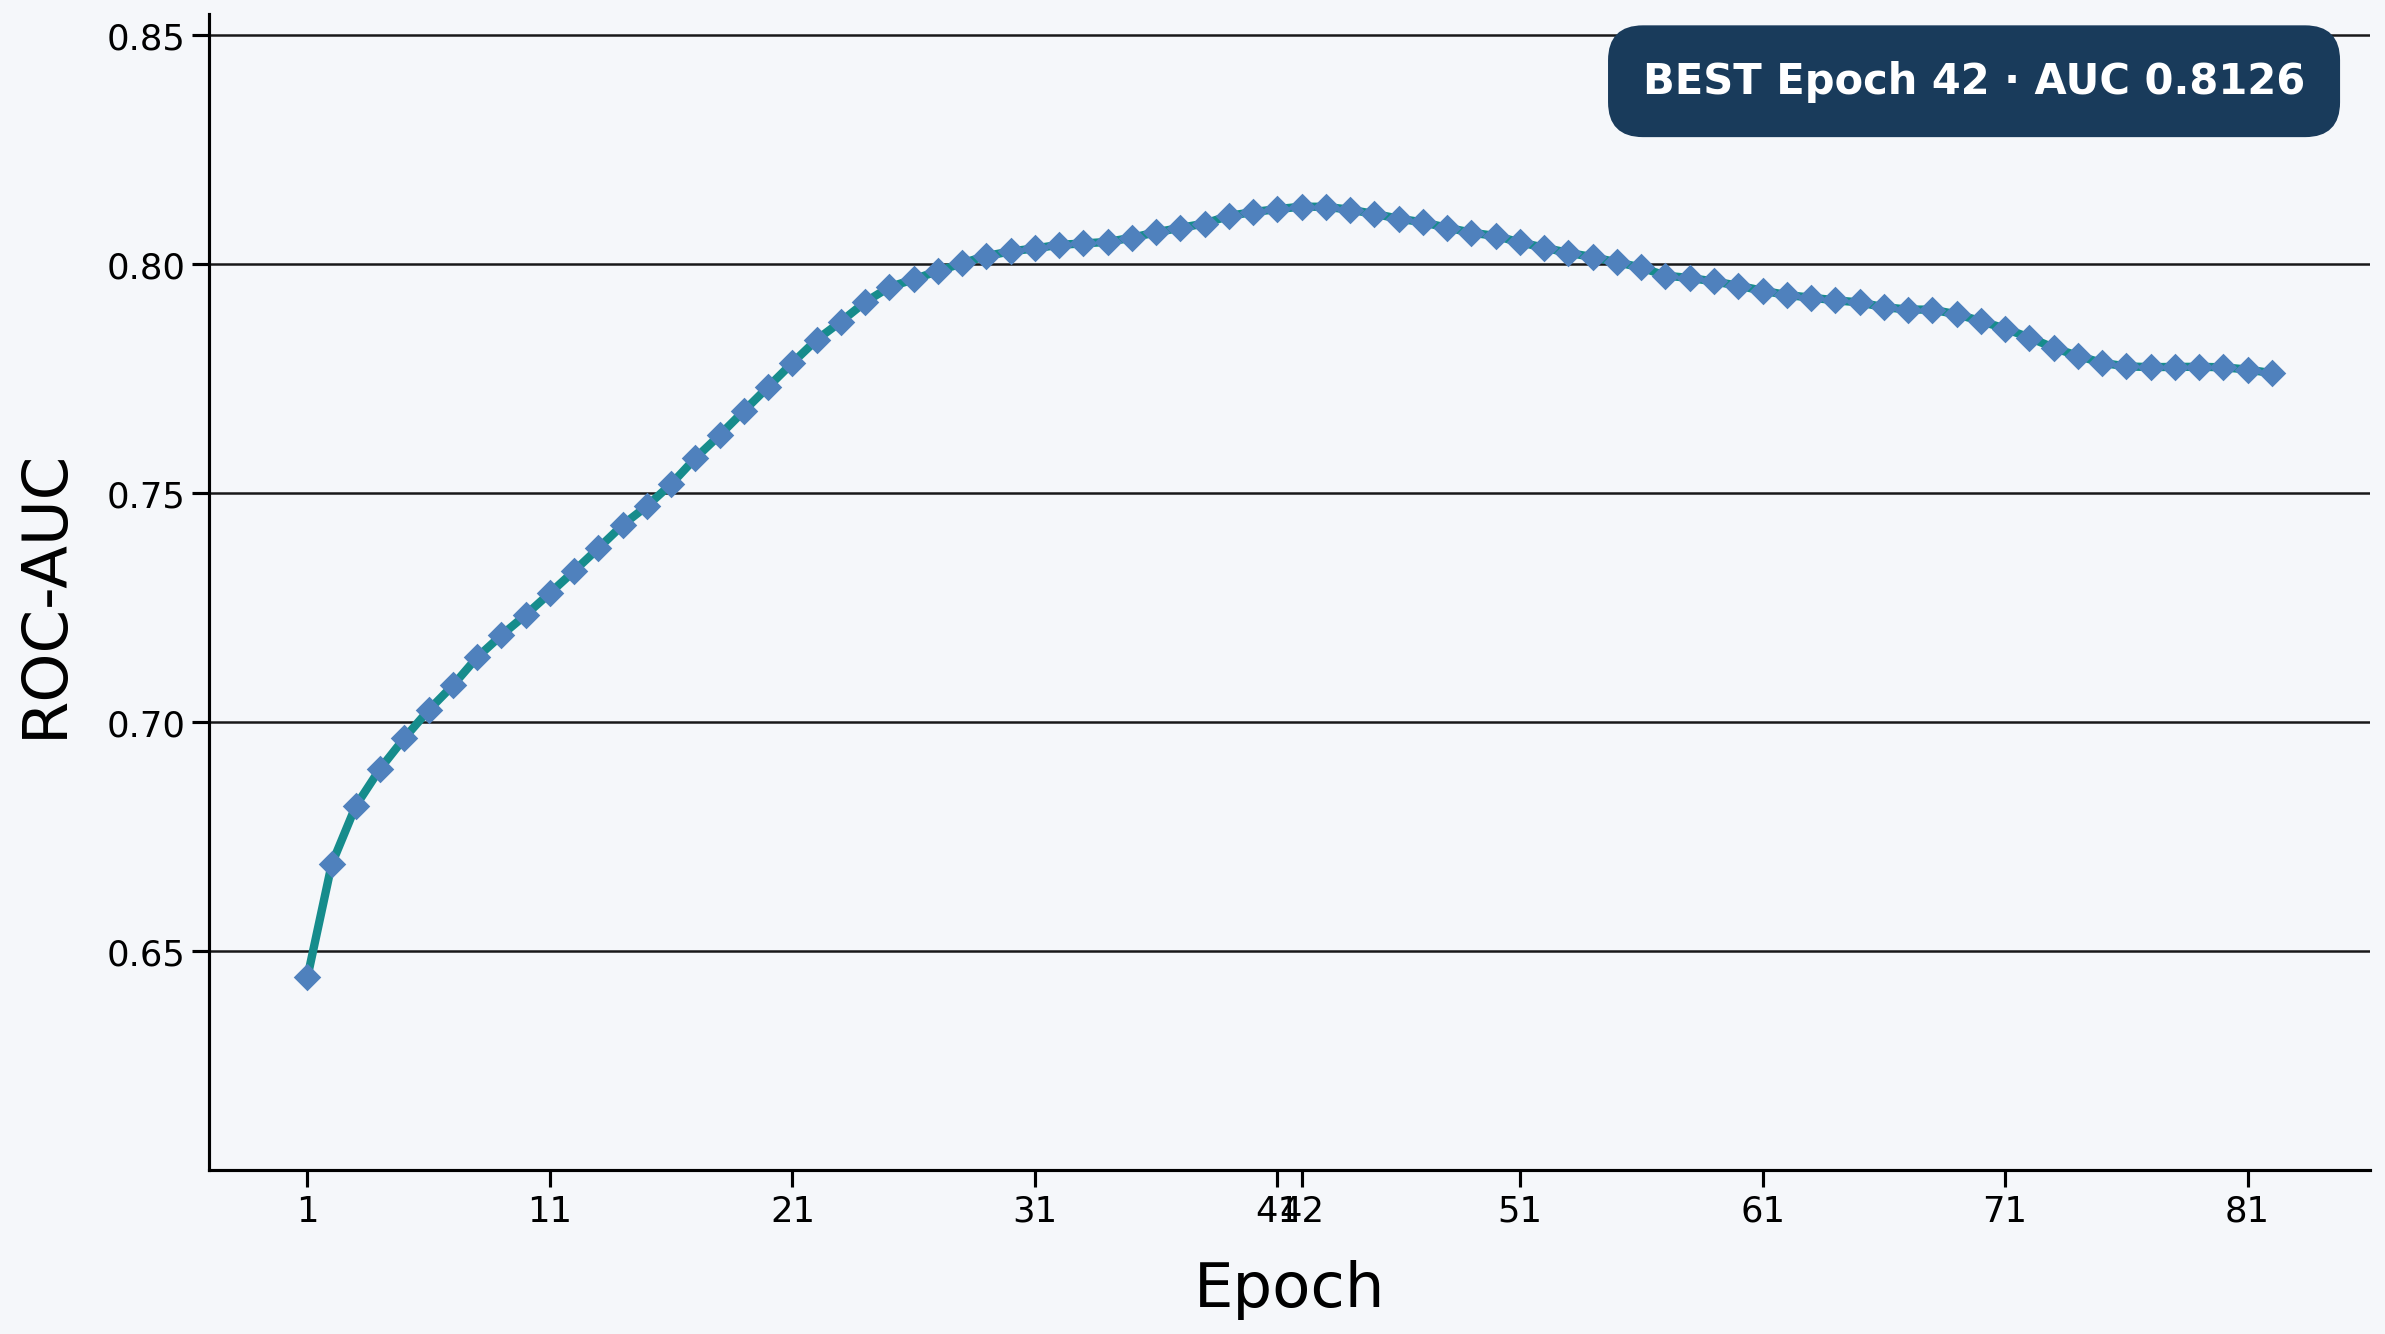


ROC-AUC graph saved successfully:
/Users/sameersalim/neeuro/output/NeuroGraphX_Step2_Validation_ROC_AUC_vs_Epoch.png


In [4]:
# ============================================================
# NeuroGraphX Step 2 — Validation ROC-AUC vs Epoch Plot
# Uses the ACTUAL GraphSAGE training history
# ============================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

OUTPUT_DIR = Path("/Users/sameersalim/neeuro/output")

HISTORY_OUTPUT = (
    OUTPUT_DIR / "NeuroGraphX_Brain_GNN_Training_History.csv"
)

ROC_AUC_PLOT_OUTPUT = (
    OUTPUT_DIR / "NeuroGraphX_Step2_Validation_ROC_AUC_vs_Epoch.png"
)


# ------------------------------------------------------------
# 2. Load actual training history
# ------------------------------------------------------------

if not HISTORY_OUTPUT.exists():
    raise FileNotFoundError(
        f"Training history file not found:\n{HISTORY_OUTPUT}\n\n"
        "Run your Step 2 GraphSAGE training code first."
    )

history_df = pd.read_csv(HISTORY_OUTPUT)

required_columns = ["epoch", "val_roc_auc"]

missing_columns = [
    col for col in required_columns
    if col not in history_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in training history: {missing_columns}"
    )

# Extract actual values
epochs = history_df["epoch"].to_numpy()
val_auc = history_df["val_roc_auc"].to_numpy(dtype=float)

# Remove invalid values
valid_mask = np.isfinite(val_auc)

epochs = epochs[valid_mask]
val_auc = val_auc[valid_mask]

if len(val_auc) == 0:
    raise ValueError("No valid validation ROC-AUC values found.")


# ------------------------------------------------------------
# 3. Find best epoch
# ------------------------------------------------------------

best_idx = np.argmax(val_auc)

best_epoch = int(epochs[best_idx])
best_auc = float(val_auc[best_idx])

print("Best Epoch:", best_epoch)
print(f"Best Validation ROC-AUC: {best_auc:.6f}")


# ------------------------------------------------------------
# 4. Create the graph
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 9), dpi=150)

# Background
fig.patch.set_facecolor("#f5f7fa")
ax.set_facecolor("#f5f7fa")

# Validation ROC-AUC curve
ax.plot(
    epochs,
    val_auc,
    color="#168c8c",
    linewidth=4,
    marker="D",
    markersize=8,
    markerfacecolor="#4f81bd",
    markeredgecolor="#4f81bd",
    markeredgewidth=1.2,
    zorder=3
)


# ------------------------------------------------------------
# 5. Axis labels and formatting
# ------------------------------------------------------------

ax.set_xlabel(
    "Epoch",
    fontsize=30,
    labelpad=15
)

ax.set_ylabel(
    "ROC-AUC",
    fontsize=30,
    labelpad=15
)

ax.tick_params(
    axis="both",
    labelsize=17,
    width=1.5,
    length=8
)

# Use actual epoch numbers
if len(epochs) <= 15:
    ax.set_xticks(epochs)
else:
    # Avoid overcrowding for longer training runs
    tick_epochs = list(epochs[::10])

    if best_epoch not in tick_epochs:
        tick_epochs.append(best_epoch)

    ax.set_xticks(sorted(set(tick_epochs)))


# ------------------------------------------------------------
# 6. Y-axis range
# ------------------------------------------------------------

auc_min = np.min(val_auc)
auc_max = np.max(val_auc)

padding = max((auc_max - auc_min) * 0.25, 0.01)

ax.set_ylim(
    max(0.0, auc_min - padding),
    min(1.0, auc_max + padding)
)


# ------------------------------------------------------------
# 7. Gridlines and borders
# ------------------------------------------------------------

ax.grid(
    axis="y",
    color="black",
    linewidth=1.2,
    alpha=0.9
)

ax.grid(
    axis="x",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)


# ------------------------------------------------------------
# 8. Best epoch banner
# ------------------------------------------------------------

ax.text(
    0.97,
    0.96,
    f"BEST Epoch {best_epoch} · AUC {best_auc:.4f}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=20,
    fontweight="bold",
    color="white",
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="#193b5b",
        edgecolor="#193b5b",
        linewidth=1.5
    )
)


# ------------------------------------------------------------
# 9. Save and display
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    ROC_AUC_PLOT_OUTPUT,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("\nROC-AUC graph saved successfully:")
print(ROC_AUC_PLOT_OUTPUT)

NEUROGRAPHX PHASE 2 — strict leakage-safe brain + clinical LSTM | device: cpu
Brain visits after de-duplication: 11633
Leakage-safe clinical features: 34
Combined shape: (11633, 102) | visits matched to clinical data: 9895/11633
Rows — train: 9393 val: 1156 test: 1084
Combined feature dimension: 98 (brain 64 + clinical 34)
Sequences — train: 9393 val: 1156 test: 1084
BrainClinicalLSTM(
  (lstm): LSTM(98, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=1, bias=True)
)

Training longitudinal LSTM...
Epoch 001 | Train 0.6703 | Val 1.6519 | Val ROC-AUC 0.8600
Epoch 002 | Train 0.3893 | Val 1.5092 | Val ROC-AUC 0.8775
Epoch 003 | Train 0.2877 | Val 2.2387 | Val ROC-AUC 0.8662
Epoch 004 | Train 0.2728 | Val 3.4085 | Val ROC-AUC 0.8285
Epoch 005 | Train 0.2286 | Val 2.8758 | Val ROC-AUC 0.8528
Epoch 006 | Train 0.1629 | Val 3.6334 | Val ROC-AUC 0.8439
Epoch 007 | Train 0.1737 | Val 4.5466 | Val R

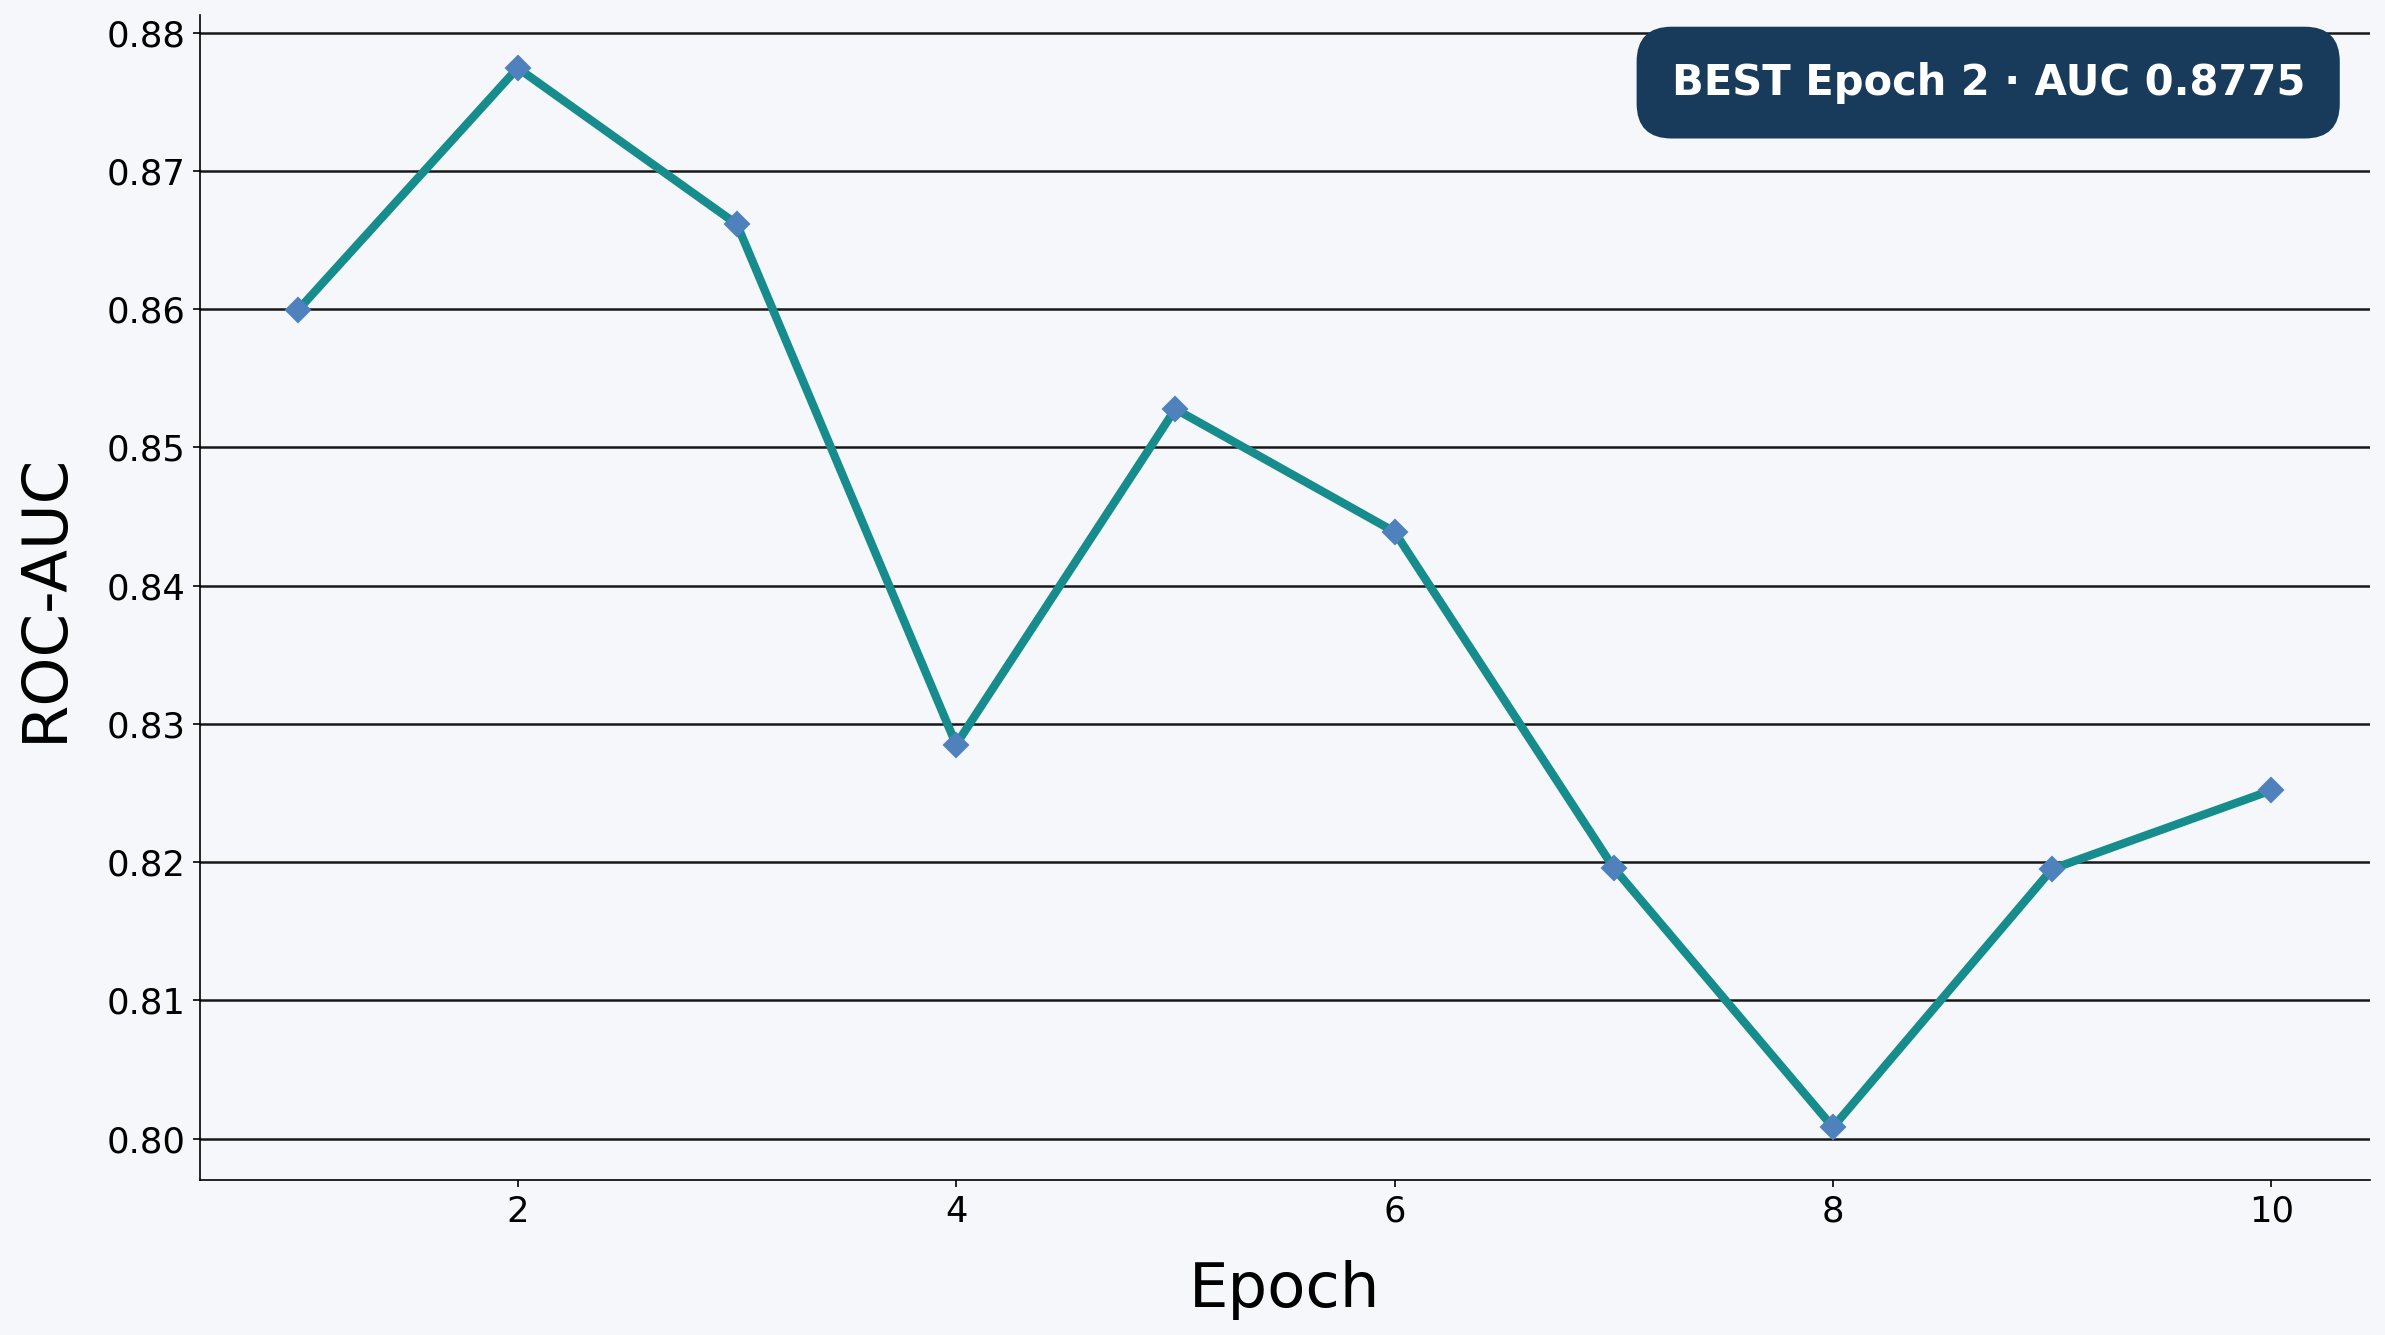

Validation ROC-AUC plot saved to: /Users/sameersalim/neeuro/output/NeuroGraphX_Phase2_Validation_ROC_AUC_vs_Epoch.png

Classification Report — Phase 2 Brain + Clinical LSTM
                 precision    recall  f1-score   support

Non-Alzheimer's     0.9876    0.9381    0.9622      1017
    Alzheimer's     0.4661    0.8209    0.5946        67

       accuracy                         0.9308      1084
      macro avg     0.7268    0.8795    0.7784      1084
   weighted avg     0.9553    0.9308    0.9395      1084


Final test performance:
  Best_Validation_ROC_AUC   : 0.8774586068632286
  Best_Epoch                : 2
  Test_Loss                 : 0.7774052294417941
  ROC_AUC                   : 0.9461101571787082
  PR_AUC                    : 0.7080613324716345
  Accuracy                  : 0.9308118081180812
  Balanced_Accuracy         : 0.8794743098665962
  Precision                 : 0.4661016949152542
  Recall_Sensitivity        : 0.8208955223880597
  Specificity               : 0.9

In [5]:
# NeuroGraphX Phase 2 — strict leakage-safe brain GNN + clinical LSTM
#
# Fuses the 64-D GraphSAGE brain embeddings with a leakage-safe subset of
# clinical/cognitive features (no target, no future-derived, no diagnosis,
# no identifiers, no raw ST* brain measurements) into per-visit vectors,
# then trains a longitudinal LSTM over each patient's visit sequence to
# predict FUTURE_ALZHEIMER_LABEL.

import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report,
)
from torch.utils.data import Dataset, DataLoader

BRAIN_GNN_PATH = "/Users/sameersalim/neeuro/output/NeuroGraphX_Brain_GNN_Embeddings.csv"
ORIGINAL_DATA_PATH = "/Users/sameersalim/neeuro/ADNI_UCSFFSX7_Clean_Brain_Visit_Dataset.csv"
OUTPUT_DIR = "/Users/sameersalim/neeuro/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

COMBINED_OUTPUT = os.path.join(OUTPUT_DIR, "Brain_GNN_Clinical_Combined_Features_STRICT_LEAKAGE_SAFE.csv")
MODEL_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Clinical_LSTM_STRICT_LEAKAGE_SAFE.pt")
PREDICTION_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Brain_Clinical_LSTM_Predictions_STRICT_LEAKAGE_SAFE.csv")
METRICS_OUTPUT = os.path.join(OUTPUT_DIR, "Brain_Clinical_LSTM_Metrics_STRICT_LEAKAGE_SAFE.csv")
PREPROCESSING_OUTPUT = os.path.join(OUTPUT_DIR, "Brain_Clinical_LSTM_Preprocessing_Statistics.csv")

SEED = 42
MAX_SEQUENCE_LENGTH = 10
BATCH_SIZE = 64
HIDDEN_DIM, NUM_LAYERS, DROPOUT = 128, 2, 0.30
LEARNING_RATE, WEIGHT_DECAY = 1e-3, 1e-4
EPOCHS, PATIENCE, CLASSIFICATION_THRESHOLD = 50, 8, 0.50

np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("NEUROGRAPHX PHASE 2 — strict leakage-safe brain + clinical LSTM | device:", DEVICE)


def fit_median_imputer(X):
    medians = np.nanmedian(np.asarray(X, dtype=np.float64), axis=0)
    return np.where(np.isfinite(medians), medians, 0.0)


def apply_median_imputer(X, medians):
    X = np.asarray(X, dtype=np.float64).copy()
    rows, cols = np.where(~np.isfinite(X))
    X[rows, cols] = medians[cols]
    return X


# --- Load GraphSAGE brain embeddings ---
brain = pd.read_csv(BRAIN_GNN_PATH, low_memory=False)
embedding_cols = sorted(
    [c for c in brain.columns if c.startswith("BRAIN_EMBED_")],
    key=lambda c: int(c.split("_")[-1]),
)
assert len(embedding_cols) == 64

brain["RID"] = pd.to_numeric(brain["RID"], errors="coerce")
brain["EXAMDATE"] = pd.to_datetime(brain["EXAMDATE"], errors="coerce")
for col in embedding_cols:
    brain[col] = pd.to_numeric(brain[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

brain_small = brain[["RID", "EXAMDATE", "SPLIT", "FUTURE_ALZHEIMER_LABEL"] + embedding_cols].copy()
if brain_small.duplicated(subset=["RID", "EXAMDATE"], keep=False).any():
    agg = {"SPLIT": "first", "FUTURE_ALZHEIMER_LABEL": "first", **{c: "median" for c in embedding_cols}}
    brain_small = brain_small.groupby(["RID", "EXAMDATE"], as_index=False).agg(agg)
print(f"Brain visits after de-duplication: {len(brain_small)}")

# --- Load clinical data & apply strict leakage exclusions ---
clinical = pd.read_csv(ORIGINAL_DATA_PATH, low_memory=False)
clinical["RID"] = pd.to_numeric(clinical["RID"], errors="coerce")
clinical["EXAMDATE"] = pd.to_datetime(clinical["EXAMDATE"], errors="coerce")

target_columns = {"FUTURE_ALZHEIMER", "FUTURE_ALZHEIMER_LABEL"}
future_leakage_columns = {"DAYS_TO_FIRST_AD"}
diagnosis_columns = {"DIAGNOSIS", "DXAD", "DXMCI", "DXNORM"}
brain_original_columns = {c for c in clinical.columns if c.startswith("ST")}
identifier_columns = {"RID", "EXAMDATE", "SPLIT", "Unnamed: 5", "IMAGEUID"}
excluded_columns = (
    target_columns | future_leakage_columns | diagnosis_columns
    | brain_original_columns | identifier_columns
)

clinical_feature_cols = [
    c for c in clinical.columns
    if c not in excluded_columns and pd.api.types.is_numeric_dtype(clinical[c])
]
forbidden = target_columns | future_leakage_columns | diagnosis_columns
assert not (forbidden & set(clinical_feature_cols)), "Leakage-safe column exclusion failed."
print(f"Leakage-safe clinical features: {len(clinical_feature_cols)}")

clinical_small = clinical[["RID", "EXAMDATE"] + clinical_feature_cols].copy()
for col in clinical_feature_cols:
    clinical_small[col] = pd.to_numeric(clinical_small[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
clinical_small = clinical_small.dropna(subset=["RID", "EXAMDATE"])
if clinical_small.duplicated(subset=["RID", "EXAMDATE"], keep=False).any():
    clinical_small = clinical_small.groupby(["RID", "EXAMDATE"], as_index=False)[clinical_feature_cols].median()

# --- Merge brain + clinical ---
combined = brain_small.merge(clinical_small, on=["RID", "EXAMDATE"], how="left", validate="one_to_one")
combined = combined.sort_values(["RID", "EXAMDATE"]).reset_index(drop=True)
matched = combined[clinical_feature_cols].notna().any(axis=1).sum()
print(f"Combined shape: {combined.shape} | visits matched to clinical data: {matched}/{len(combined)}")

combined["FUTURE_ALZHEIMER_LABEL"] = pd.to_numeric(combined["FUTURE_ALZHEIMER_LABEL"], errors="coerce").astype(int)
combined["SPLIT"] = combined["SPLIT"].astype(str).str.strip().str.upper()
assert set(combined["SPLIT"].unique()) <= {"TRAIN", "VAL", "TEST"}
assert (combined.groupby("RID")["SPLIT"].nunique() == 1).all(), "Patient leakage across splits."

train_mask = combined["SPLIT"] == "TRAIN"
val_mask = combined["SPLIT"] == "VAL"
test_mask = combined["SPLIT"] == "TEST"
print(f"Rows — train: {train_mask.sum()} val: {val_mask.sum()} test: {test_mask.sum()}")


def split_arrays(cols):
    return (
        combined.loc[train_mask, cols].astype(float).values,
        combined.loc[val_mask, cols].astype(float).values,
        combined.loc[test_mask, cols].astype(float).values,
    )


# --- Train-only imputation + standardization (brain & clinical separately) ---
train_brain_raw, val_brain_raw, test_brain_raw = split_arrays(embedding_cols)
train_clinical_raw, val_clinical_raw, test_clinical_raw = split_arrays(clinical_feature_cols)

brain_medians = fit_median_imputer(train_brain_raw)
train_brain, val_brain, test_brain = (
    apply_median_imputer(a, brain_medians) for a in (train_brain_raw, val_brain_raw, test_brain_raw)
)

clinical_medians = fit_median_imputer(train_clinical_raw)
train_clinical, val_clinical, test_clinical = (
    apply_median_imputer(a, clinical_medians) for a in (train_clinical_raw, val_clinical_raw, test_clinical_raw)
)

brain_scaler = StandardScaler().fit(train_brain)
train_brain, val_brain, test_brain = (brain_scaler.transform(a) for a in (train_brain, val_brain, test_brain))

clinical_scaler = StandardScaler().fit(train_clinical)
train_clinical, val_clinical, test_clinical = (
    clinical_scaler.transform(a) for a in (train_clinical, val_clinical, test_clinical)
)

for name, arr in [
    ("train_brain", train_brain), ("val_brain", val_brain), ("test_brain", test_brain),
    ("train_clinical", train_clinical), ("val_clinical", val_clinical), ("test_clinical", test_clinical),
]:
    assert np.isfinite(arr).all(), f"{name} contains NaN/Inf after preprocessing."

FEATURE_DIM = len(embedding_cols) + len(clinical_feature_cols)
print(f"Combined feature dimension: {FEATURE_DIM} "
      f"(brain {len(embedding_cols)} + clinical {len(clinical_feature_cols)})")

# --- Rebuild processed dataframe & save ---
clinical_processed_cols = [f"CLINICAL_{i + 1}" for i in range(len(clinical_feature_cols))]
processed = combined[["RID", "EXAMDATE", "SPLIT", "FUTURE_ALZHEIMER_LABEL"]].copy()
for cols, arrs in [
    (embedding_cols, (train_brain, val_brain, test_brain)),
    (clinical_processed_cols, (train_clinical, val_clinical, test_clinical)),
]:
    processed[cols] = np.nan
    for mask, arr in zip((train_mask, val_mask, test_mask), arrs):
        processed.loc[mask, cols] = arr

feature_cols = embedding_cols + clinical_processed_cols
assert processed[feature_cols].isna().sum().sum() == 0
processed.to_csv(COMBINED_OUTPUT, index=False)

pd.DataFrame(
    [
        {"Feature_Type": "BRAIN_GNN", "Feature_Name": c, "Original_Clinical_Name": "",
         "Train_Imputation_Median": float(brain_medians[i])}
        for i, c in enumerate(embedding_cols)
    ] + [
        {"Feature_Type": "CLINICAL", "Feature_Name": c, "Original_Clinical_Name": clinical_feature_cols[i],
         "Train_Imputation_Median": float(clinical_medians[i])}
        for i, c in enumerate(clinical_processed_cols)
    ]
).to_csv(PREPROCESSING_OUTPUT, index=False)

# --- Build longitudinal patient sequences ---
X_all = processed[feature_cols].astype(np.float32).values
y_all = processed["FUTURE_ALZHEIMER_LABEL"].astype(np.float32).values
rids = processed["RID"].values
dates = processed["EXAMDATE"].values
splits = processed["SPLIT"].astype(str).str.upper().values


def create_patient_sequences(X, y, rids, dates, splits, max_len):
    sequences = []
    for rid in np.unique(rids):
        idx = np.where(rids == rid)[0]
        idx = idx[np.argsort(dates[idx])]
        patient_split = np.unique(splits[idx])
        assert len(patient_split) == 1, f"Patient {rid} spans multiple splits."
        for end in range(1, len(idx) + 1):
            start = max(0, end - max_len)
            sequences.append({
                "RID": rid, "SPLIT": patient_split[0], "DATE": dates[idx[end - 1]],
                "X": X[idx[start:end]].astype(np.float32), "Y": float(y[idx[end - 1]]),
            })
    return sequences


all_sequences = create_patient_sequences(X_all, y_all, rids, dates, splits, MAX_SEQUENCE_LENGTH)
train_sequences = [s for s in all_sequences if s["SPLIT"] == "TRAIN"]
val_sequences = [s for s in all_sequences if s["SPLIT"] == "VAL"]
test_sequences = [s for s in all_sequences if s["SPLIT"] == "TEST"]
print(f"Sequences — train: {len(train_sequences)} val: {len(val_sequences)} test: {len(test_sequences)}")

train_patient_ids = {s["RID"] for s in train_sequences}
val_patient_ids = {s["RID"] for s in val_sequences}
test_patient_ids = {s["RID"] for s in test_sequences}
assert not (train_patient_ids & val_patient_ids)
assert not (train_patient_ids & test_patient_ids)
assert not (val_patient_ids & test_patient_ids)


class LongitudinalDataset(Dataset):
    def __init__(self, sequences, max_length, feature_dim):
        self.sequences, self.max_length, self.feature_dim = sequences, max_length, feature_dim

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        item = self.sequences[index]
        x, length = item["X"], len(item["X"])
        padded = np.zeros((self.max_length, self.feature_dim), dtype=np.float32)
        mask = np.zeros(self.max_length, dtype=np.float32)
        padded[:length] = x  # left-aligned: real visits first, padding after
        mask[:length] = 1.0
        return torch.tensor(padded), torch.tensor(mask), torch.tensor(item["Y"], dtype=torch.float32)


train_loader = DataLoader(LongitudinalDataset(train_sequences, MAX_SEQUENCE_LENGTH, FEATURE_DIM),
                           batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(LongitudinalDataset(val_sequences, MAX_SEQUENCE_LENGTH, FEATURE_DIM),
                         batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(LongitudinalDataset(test_sequences, MAX_SEQUENCE_LENGTH, FEATURE_DIM),
                          batch_size=BATCH_SIZE, shuffle=False)


class BrainClinicalLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.30):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                             dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, x, mask):
        # pack_padded_sequence makes the LSTM skip padding steps entirely,
        # instead of running its gates over zero-vectors before the real visits.
        lengths = mask.sum(dim=1).long().cpu()
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        last_output = h_n[-1]  # final layer's hidden state at each sequence's true last step
        return self.classifier(self.dropout(last_output)).squeeze(1)


model = BrainClinicalLSTM(FEATURE_DIM, HIDDEN_DIM, NUM_LAYERS, DROPOUT).to(DEVICE)
print(model)

train_labels = np.array([s["Y"] for s in train_sequences])
pos_weight = (train_labels == 0).sum() / (train_labels == 1).sum()
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


def evaluate(model, loader):
    model.eval()
    all_probs, all_labels, total_loss, total_n = [], [], 0.0, 0
    with torch.no_grad():
        for x, mask, y in loader:
            x, mask, y = x.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            logits = model(x, mask)
            loss = criterion(logits, y)
            total_loss += loss.item() * len(y)
            total_n += len(y)
            all_probs.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return total_loss / max(total_n, 1), np.array(all_labels), np.array(all_probs)


print("\nTraining longitudinal LSTM...")
best_val_auc, best_epoch, no_improve = -np.inf, None, 0
# Store validation ROC-AUC for every epoch
epoch_history = []
val_auc_history = []
# Test ROC-AUC per epoch: recorded for reporting only (epoch selection uses validation only)
test_auc_history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, n = 0.0, 0
    for x, mask, y in train_loader:
        x, mask, y = x.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x, mask), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running_loss += loss.item() * len(y)
        n += len(y)

    val_loss, val_y, val_prob = evaluate(model, val_loader)
    val_auc = roc_auc_score(val_y, val_prob) if len(np.unique(val_y)) > 1 else np.nan
    epoch_history.append(epoch)
    val_auc_history.append(val_auc)

    # Restore the RNG state afterwards so monitoring the test set does not change training
    rng_state = torch.get_rng_state()
    _, test_y_epoch, test_prob_epoch = evaluate(model, test_loader)
    torch.set_rng_state(rng_state)
    test_auc_epoch = roc_auc_score(test_y_epoch, test_prob_epoch) if len(np.unique(test_y_epoch)) > 1 else np.nan
    test_auc_history.append(test_auc_epoch)

    print(f"Epoch {epoch:03d} | Train {running_loss / n:.4f} | Val {val_loss:.4f} | Val ROC-AUC {val_auc:.4f}"
          f" | Test ROC-AUC {test_auc_epoch:.4f}")

    if np.isfinite(val_auc) and val_auc > best_val_auc:
        best_val_auc, best_epoch, no_improve = val_auc, epoch, 0
        torch.save({
            "model_state_dict": model.state_dict(), "input_dim": FEATURE_DIM,
            "hidden_dim": HIDDEN_DIM, "num_layers": NUM_LAYERS, "dropout": DROPOUT,
            "max_sequence_length": MAX_SEQUENCE_LENGTH,
            "clinical_feature_names": clinical_feature_cols, "brain_embedding_names": embedding_cols,
        }, MODEL_OUTPUT)
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (best epoch {best_epoch})")
            break

model.load_state_dict(torch.load(MODEL_OUTPUT, map_location=DEVICE)["model_state_dict"])
# ==================================================
# Validation ROC-AUC vs Epoch — Actual Phase 2 Data
# ==================================================

import matplotlib.pyplot as plt

epochs_plot = np.array(epoch_history)
auc_plot = np.array(val_auc_history)

# Find best epoch from the actual recorded history
best_idx = np.nanargmax(auc_plot)
plot_best_epoch = epochs_plot[best_idx]
plot_best_auc = auc_plot[best_idx]

plt.figure(figsize=(16, 9), dpi=150)

# Background
plt.gcf().patch.set_facecolor("#f5f7fa")
plt.gca().set_facecolor("#f5f7fa")

# Validation ROC-AUC curve
plt.plot(
    epochs_plot,
    auc_plot,
    color="#168c8c",
    linewidth=4,
    marker="D",
    markersize=8,
    markerfacecolor="#4f81bd",
    markeredgecolor="#4f81bd",
    zorder=3
)

# Axis labels
plt.xlabel("Epoch", fontsize=30, labelpad=15)
plt.ylabel("ROC-AUC", fontsize=30, labelpad=15)

# Tick formatting
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)

# Horizontal gridlines
plt.grid(
    axis="y",
    color="black",
    linewidth=1.2,
    alpha=0.9
)

plt.grid(axis="x", visible=False)

# Remove top and right borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

# Best epoch banner
plt.text(
    0.97,
    0.96,
    f"BEST Epoch {plot_best_epoch} · AUC {plot_best_auc:.4f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=20,
    fontweight="bold",
    color="white",
    bbox=dict(
        boxstyle="round,pad=0.8",
        facecolor="#193b5b",
        edgecolor="#193b5b",
        linewidth=1.5
    )
)

plt.tight_layout()

# Save inside your existing output directory
ROC_AUC_PLOT_OUTPUT = os.path.join(
    OUTPUT_DIR,
    "NeuroGraphX_Phase2_Validation_ROC_AUC_vs_Epoch.png"
)

plt.savefig(
    ROC_AUC_PLOT_OUTPUT,
    dpi=300,
    bbox_inches="tight",
    facecolor=plt.gcf().get_facecolor()
)

plt.show()

print(f"Validation ROC-AUC plot saved to: {ROC_AUC_PLOT_OUTPUT}")

# ==================================================
# Test ROC-AUC vs Epoch — same style; epoch chosen on validation
# ==================================================
test_auc_plot = np.array(test_auc_history)
sel_idx = int(np.where(epochs_plot == best_epoch)[0][0])

plt.figure(figsize=(16, 9), dpi=150)
plt.gcf().patch.set_facecolor("#f5f7fa")
plt.gca().set_facecolor("#f5f7fa")

plt.plot(
    epochs_plot,
    test_auc_plot,
    color="#c0504d",
    linewidth=4,
    marker="D",
    markersize=8,
    markerfacecolor="#7f2a28",
    markeredgecolor="#7f2a28",
    zorder=3
)
plt.axvline(best_epoch, color="#193b5b", linestyle="--", linewidth=2, zorder=2)
plt.plot(best_epoch, test_auc_plot[sel_idx], marker="o", markersize=18, markerfacecolor="none",
         markeredgecolor="#193b5b", markeredgewidth=3, zorder=4)

plt.xlabel("Epoch", fontsize=30, labelpad=15)
plt.ylabel("Test ROC-AUC", fontsize=30, labelpad=15)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.grid(axis="y", color="black", linewidth=1.2, alpha=0.9)
plt.grid(axis="x", visible=False)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.text(
    0.97,
    0.96,
    f"Selected Epoch {best_epoch} (by validation) · Test AUC {test_auc_plot[sel_idx]:.4f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=20,
    fontweight="bold",
    color="white",
    bbox=dict(boxstyle="round,pad=0.8", facecolor="#193b5b", edgecolor="#193b5b", linewidth=1.5)
)
plt.tight_layout()

TEST_AUC_PLOT_OUTPUT = os.path.join(OUTPUT_DIR, "NeuroGraphX_Phase2_Test_ROC_AUC_vs_Epoch.png")
plt.savefig(TEST_AUC_PLOT_OUTPUT, dpi=300, bbox_inches="tight", facecolor=plt.gcf().get_facecolor())
plt.show()

pd.DataFrame({"Epoch": epochs_plot, "Val_ROC_AUC": auc_plot, "Test_ROC_AUC": test_auc_plot}).to_csv(
    os.path.join(OUTPUT_DIR, "NeuroGraphX_Phase2_ROC_AUC_by_Epoch.csv"), index=False)
print(f"Test ROC-AUC plot saved to: {TEST_AUC_PLOT_OUTPUT}")

test_loss, test_y, test_prob = evaluate(model, test_loader)
test_pred = (test_prob >= CLASSIFICATION_THRESHOLD).astype(int)
# --- Classification Report ---
print("\nClassification Report — Phase 2 Brain + Clinical LSTM")

classification_report_text = classification_report(
    test_y,
    test_pred,
    labels=[0, 1],
    target_names=["Non-Alzheimer's", "Alzheimer's"],
    digits=4,
    zero_division=0,
)

print(classification_report_text)
tn, fp, fn, tp = confusion_matrix(test_y, test_pred, labels=[0, 1]).ravel()

test_metrics = {
    "Best_Validation_ROC_AUC": best_val_auc, "Best_Epoch": best_epoch, "Test_Loss": test_loss,
    "ROC_AUC": roc_auc_score(test_y, test_prob), "PR_AUC": average_precision_score(test_y, test_prob),
    "Accuracy": accuracy_score(test_y, test_pred),
    "Balanced_Accuracy": balanced_accuracy_score(test_y, test_pred),
    "Precision": precision_score(test_y, test_pred, zero_division=0),
    "Recall_Sensitivity": recall_score(test_y, test_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
    "F1": f1_score(test_y, test_pred, zero_division=0),
    "Classification_Threshold": CLASSIFICATION_THRESHOLD,
    "True_Negatives": int(tn), "False_Positives": int(fp), "False_Negatives": int(fn), "True_Positives": int(tp),
}
print("\nFinal test performance:")
for k, v in test_metrics.items():
    print(f"  {k:26s}: {v}")

pd.DataFrame(list(test_metrics.items()), columns=["Metric", "Value"]).to_csv(METRICS_OUTPUT, index=False)
pd.DataFrame([
    {"RID": s["RID"], "EXAMDATE": s["DATE"], "FUTURE_ALZHEIMER_LABEL": int(a),
     "LSTM_AD_PROBABILITY": float(p), "LSTM_PREDICTION": int(pred)}
    for s, p, a, pred in zip(test_sequences, test_prob, test_y, test_pred)
]).to_csv(PREDICTION_OUTPUT, index=False)

print(f"\nPHASE 2 COMPLETE — model: {MODEL_OUTPUT}")
# --- Classification Report ---
print("\nClassification Report — Phase 2 Brain + Clinical LSTM")

classification_report_dict = classification_report(
    test_y,
    test_pred,
    labels=[0, 1],
    target_names=["Non-Alzheimer's", "Alzheimer's"],
    output_dict=True,
    zero_division=0,
)

classification_report_text = classification_report(
    test_y,
    test_pred,
    labels=[0, 1],
    target_names=["Non-Alzheimer's", "Alzheimer's"],
    digits=4,
    zero_division=0,
)

print(classification_report_text)

# Save classification report
classification_report_df = pd.DataFrame(classification_report_dict).transpose()
classification_report_df.to_csv(
    os.path.join(OUTPUT_DIR, "Brain_Clinical_LSTM_Classification_Report.csv")
)


NeuroGraphX: ROC-AUC = 0.8971 (95% CI 0.822–0.960); sensitivity 0.853, specificity 0.750 at threshold 0.400


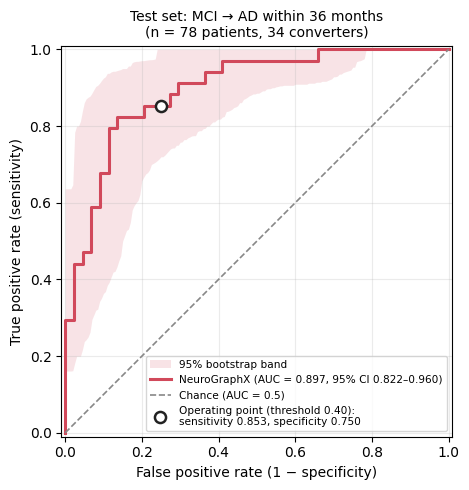

In [16]:
# ----------------------------------------------------------------------------
# ROC curve (Figure 3) — recomputed from saved test labels + continuous predictions
# ----------------------------------------------------------------------------
# MODEL = "corrected"  -> final NeuroGraphX (baseline-MCI -> AD within 36 months, 185 ST features)
# MODEL = "phase2_old" -> Phase 2 strict leakage-safe LSTM from the cell above (old FUTURE_ALZHEIMER_LABEL)
MODEL = "corrected"

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

ROOT = Path("/Users/sameersalim/neeuro")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "pdf.fonttype": 42})

if MODEL == "corrected":
    OUT = ROOT / "output_corrected"
    FULL = "NeuroGraphX full (GNN brain + clinical + LSTM)"
    pred = pd.read_csv(OUT / "test_predictions_all_models.csv")
    y, p = pred["LABEL"].to_numpy(), pred[FULL].to_numpy()
    thr = float(pd.read_csv(OUT / "test_metrics_all_models.csv").set_index("Model").loc[FULL, "Threshold"])
    title = f"Test set: MCI → AD within 36 months\n(n = {len(y)} patients, {int(y.sum())} converters)"
    name, color = "NeuroGraphX", "#D1495B"
else:
    OUT = ROOT / "output"
    pred = pd.read_csv(OUT / "NeuroGraphX_Brain_Clinical_LSTM_Predictions_STRICT_LEAKAGE_SAFE.csv")
    y, p = pred["FUTURE_ALZHEIMER_LABEL"].to_numpy(), pred["LSTM_AD_PROBABILITY"].to_numpy()
    m = pd.read_csv(OUT / "Brain_Clinical_LSTM_Metrics_STRICT_LEAKAGE_SAFE.csv").set_index("Metric")["Value"]
    thr = float(m["Classification_Threshold"])
    title = f"Test set: Phase 2 LSTM (old label)\n(n = {len(y)} visits, {int(y.sum())} positive)"
    name, color = "Phase 2 LSTM", "#2E86AB"

auc = roc_auc_score(y, p)
fpr, tpr, _ = roc_curve(y, p)
sens, spec = (p[y == 1] >= thr).mean(), (p[y == 0] < thr).mean()

# 95% bootstrap CI for AUC and a TPR band on a fixed FPR grid
rng = np.random.RandomState(42)
grid = np.linspace(0, 1, 201)
aucs, curves = [], []
while len(aucs) < 2000:
    i = rng.randint(0, len(y), len(y))
    if 0 < y[i].sum() < len(i):
        f, t, _ = roc_curve(y[i], p[i])
        curves.append(np.interp(grid, f, t))
        aucs.append(roc_auc_score(y[i], p[i]))
lo, hi = np.percentile(curves, [2.5, 97.5], axis=0)
ci = np.percentile(aucs, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(5.2, 5.0))
ax.fill_between(grid, lo, hi, color=color, alpha=0.15, lw=0, label="95% bootstrap band")
ax.step(fpr, tpr, where="post", color=color, lw=2.2, label=f"{name} (AUC = {auc:.3f}, 95% CI {ci[0]:.3f}–{ci[1]:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#888888", lw=1.2, label="Chance (AUC = 0.5)")
ax.plot(1 - spec, sens, "o", ms=8, mfc="white", mec="#222222", mew=1.8,
        label=f"Operating point (threshold {thr:.2f}):\nsensitivity {sens:.3f}, specificity {spec:.3f}")
ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.01), xlabel="False positive rate (1 − specificity)",
       ylabel="True positive rate (sensitivity)")
ax.set_title(title, fontsize=10)
ax.set_aspect("equal")
ax.grid(alpha=0.25)
ax.legend(loc="lower right", fontsize=7.6, frameon=True)
plt.tight_layout()
suffix = "" if MODEL == "corrected" else "_phase2_old_label"
plt.savefig(OUT / f"roc_curve{suffix}.pdf", bbox_inches="tight")
plt.savefig(OUT / f"roc_curve{suffix}.png", dpi=200, bbox_inches="tight")
print(f"{name}: ROC-AUC = {auc:.4f} (95% CI {ci[0]:.3f}–{ci[1]:.3f}); "
      f"sensitivity {sens:.3f}, specificity {spec:.3f} at threshold {thr:.3f}")
plt.show()

In [ ]:
# ----------------------------------------------------------------------------
# Precision–Recall curve — final NeuroGraphX model, test set
# ----------------------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

OUT = "/Users/sameersalim/neeuro/output_corrected"
pred = pd.read_csv(f"{OUT}/test_predictions_all_models.csv")
y, p = pred["LABEL"], pred["NeuroGraphX full (GNN brain + clinical + LSTM)"]

precision, recall, _ = precision_recall_curve(y, p)
print(f"PR-AUC (average precision) = {average_precision_score(y, p):.4f}")

plt.figure()
plt.plot(recall, precision, color="purple")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.savefig(f"{OUT}/pr_curve.pdf", bbox_inches="tight")
plt.savefig(f"{OUT}/pr_curve.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# ----------------------------------------------------------------------------
# Confusion matrix — final NeuroGraphX model, test set, selected threshold
# ----------------------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OUT = "/Users/sameersalim/neeuro/output_corrected"
MODEL_NAME = "NeuroGraphX full (GNN brain + clinical + LSTM)"
pred = pd.read_csv(f"{OUT}/test_predictions_all_models.csv")
y, p = pred["LABEL"], pred[MODEL_NAME]

# Decision threshold selected on the validation set (Youden's J)
threshold = pd.read_csv(f"{OUT}/test_metrics_all_models.csv").set_index("Model").loc[MODEL_NAME, "Threshold"]
y_pred = (p >= threshold).astype(int)

cm = confusion_matrix(y, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"Threshold = {threshold:.3f} | TN {tn}  FP {fp}  FN {fn}  TP {tp}")
print(f"Sensitivity {tp / (tp + fn):.3f} | Specificity {tn / (tn + fp):.3f} | Accuracy {(tp + tn) / cm.sum():.3f}")

disp = ConfusionMatrixDisplay(cm, display_labels=["Stable MCI", "Converter"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix")
plt.savefig(f"{OUT}/confusion_matrix.pdf", bbox_inches="tight")
plt.savefig(f"{OUT}/confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

All 517 patients | TN 222  FP 67  FN 37  TP 191
Sensitivity 0.838 | Specificity 0.768 | Accuracy 0.799


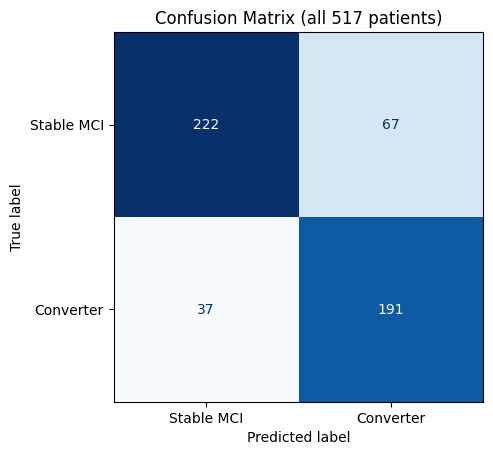

In [19]:
# ----------------------------------------------------------------------------
# Confusion matrix — ALL 517 patients (5-fold out-of-fold predictions)
# ----------------------------------------------------------------------------
# Predictions come from make_confusion_matrix_all.py: each patient is predicted by a model
# trained without them; the threshold is chosen on each fold's validation patients.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OUT = "/Users/sameersalim/neeuro/output_corrected"
oof = pd.read_csv(f"{OUT}/oof_predictions_all_patients.csv")

cm = confusion_matrix(oof["LABEL"], oof["PRED"], labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"All {len(oof)} patients | TN {tn}  FP {fp}  FN {fn}  TP {tp}")
print(f"Sensitivity {tp / (tp + fn):.3f} | Specificity {tn / (tn + fp):.3f} | Accuracy {(tp + tn) / cm.sum():.3f}")

disp = ConfusionMatrixDisplay(cm, display_labels=["Stable MCI", "Converter"])
disp.plot(cmap="Blues", colorbar=False)
plt.title(f"Confusion Matrix (all {len(oof)} patients)")
plt.savefig(f"{OUT}/confusion_matrix_all_patients.pdf", bbox_inches="tight")
plt.show()